In [1]:
import pandas as pd
import numpy as np

In [2]:
df = pd.read_csv("stock_market_clean.csv")

In [3]:
# Select Apple stock
aapl = df[df["Ticker"] == "AAPL"].copy()

# Sort chronologically
aapl = aapl.sort_values("Date").reset_index(drop=True)

# Create the prediction target
aapl["Target"] = aapl["Close"].shift(-1)

print(aapl[["Date", "Close", "Target"]].head(10))

         Date       Close      Target
0  2021-10-11  142.809998  141.509995
1  2021-10-12  141.509995  140.910004
2  2021-10-13  140.910004  143.759995
3  2021-10-14  143.759995  144.839996
4  2021-10-15  144.839996  146.550003
5  2021-10-18  146.550003  148.759995
6  2021-10-19  148.759995  149.259995
7  2021-10-20  149.259995  149.479996
8  2021-10-21  149.479996  148.690002
9  2021-10-22  148.690002  148.639999


daily return

In [4]:
aapl

,Date,Open,High,Low,Close,Adj Close,Volume,Ticker,Target
0,2021-10-11,142.270004,144.809998,141.809998,142.809998,139.292725,64452200,AAPL,141.509995
1,2021-10-12,143.229996,143.250000,141.039993,141.509995,138.024750,73035900,AAPL,140.910004
2,2021-10-13,141.240005,141.399994,139.199997,140.910004,137.439560,78762700,AAPL,143.759995
3,2021-10-14,142.110001,143.880005,141.509995,143.759995,140.219345,69907100,AAPL,144.839996
4,2021-10-15,143.770004,144.899994,143.509995,144.839996,141.272751,67940300,AAPL,146.550003
...,...,...,...,...,...,...,...,...,...
1250,2026-10-05,332.820007,336.209991,331.649994,332.890015,332.890015,34400900,AAPL,333.630005
1251,2026-10-06,332.279999,334.380005,330.619995,333.630005,333.630005,30449000,AAPL,336.670013
1252,2026-10-07,336.959991,338.670013,332.779999,336.670013,336.670013,34147900,AAPL,340.420013
1253,2026-10-08,336.820007,341.570007,335.899994,340.420013,340.420013,35332400,AAPL,336.640015


Daily Return

In [5]:
aapl["Daily_Return"] = aapl["Close"].pct_change()

MA7

In [6]:
aapl["MA7"] = aapl["Close"].rolling(7).mean()

MA30

In [7]:
aapl["MA30"] = aapl["Close"].rolling(30).mean()

In [8]:
aapl_clean = aapl.dropna(
    subset=["Daily_Return","MA7","MA30","Target"]
).copy()

In [9]:
features = [
    "Close",
    "Volume",
    "Daily_Return",
    "MA7",
    "MA30"
]

X = aapl_clean[features]

y = aapl_clean["Target"]

print(X.shape)
print(y.shape)

(1225, 5)
(1225,)


In [10]:
# Caculate split position
split_index = int(len(X) * 0.8)

# Training data
X_train = X.iloc[:split_index]
y_train = y.iloc[:split_index]

# Testing data
X_test = X.iloc[split_index:]
y_test = y.iloc[split_index:]

# Check the results
print("X_train", X_train.shape)
print("X_test", X_test.shape)
print("Y_train", X_train.shape)

X_train (980, 5)
X_test (245, 5)
Y_train (980, 5)


In [11]:
print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))

print("Training target missing:", y_train.isna().sum())
print("Testing target missing:", y_test.isna().sum())

Training observations: 980
Testing observations: 245
Training target missing: 0
Testing target missing: 0


In [12]:
from sklearn.metrics import mean_absolute_error,mean_squared_error

In [13]:
# Baseline: predict tomorrow's price using today's close
baseline_predictions = X_test["Close"]

# Evaluate baseline
baseline_mae = mean_absolute_error(
    y_test,
    baseline_predictions
)

baseline_rmse = np.sqrt(
    mean_squared_error(y_test, baseline_predictions)
)

print("Baseline MAE:", baseline_mae)
print("Baseline RMSE:", baseline_rmse)


Baseline MAE: 3.203551062759086
Baseline RMSE: 4.522188540125875


In [14]:
from sklearn.ensemble import RandomForestRegressor

In [15]:
rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=10,
    random_state=42,
    n_jobs=1
)

rf_model.fit(X_train,y_train)

,n_estimators,100
,criterion,'squared_error'
,max_depth,10
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [16]:
# Step 1: Make predictions
rf_predictions = rf_model.predict(X_test)

# Step 2: Calculate MAE
rf_mae = mean_absolute_error(
    y_test,
    rf_predictions
)

# Step 3: Calculate RMSE
rf_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        rf_predictions
    )
)

print("Random Forest MAE:", rf_mae)
print("Random Forest RMSE:", rf_rmse)

Random Forest MAE: 34.042102104829084
Random Forest RMSE: 43.19237153063182


In [17]:
print("Training Close Price:")
print(X_train["Close"].describe())

print("\nTesting Close Price:")
print(X_test["Close"].describe())

Training Close Price:
count    980.000000
mean     186.810878
std       32.159277
min      125.019997
25%      163.634998
50%      180.730003
75%      213.312500
max      259.019989
Name: Close, dtype: float64

Testing Close Price:
count    245.000000
mean     287.026204
std       27.073961
min      246.630005
25%      264.579987
50%      276.970001
75%      310.260010
max      341.070007
Name: Close, dtype: float64


In [18]:
print("Actual test price range:")
print(y_test.min(), y_test.max())

print("\nRandom Forest prediction range:")
print(rf_predictions.min(), rf_predictions.max())

Actual test price range:
246.6300048828125 341.07000732421875

Random Forest prediction range:
247.6603908843994 255.79504229736324


In [19]:
import matplotlib.pyplot as plt

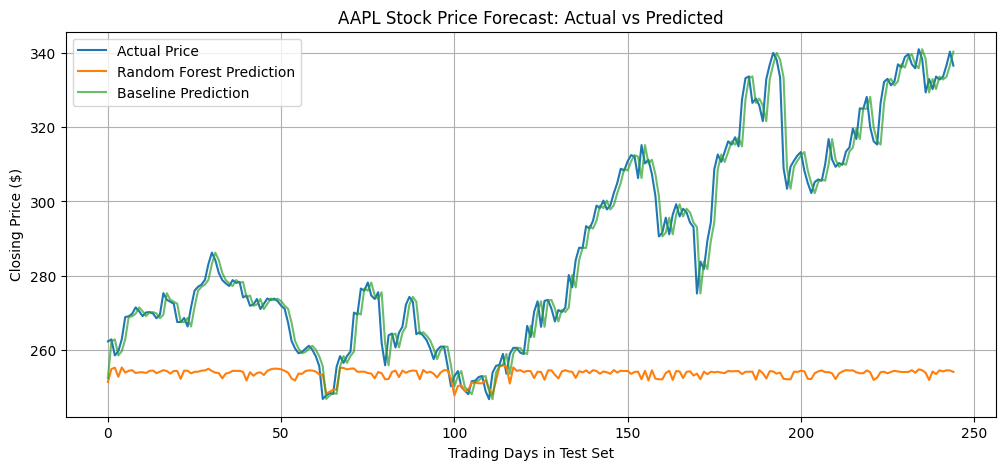

In [20]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(
    y_test.to_numpy(),
    label="Actual Price"
)

plt.plot(
    rf_predictions,
    label="Random Forest Prediction"
)

plt.plot(
    baseline_predictions.to_numpy(),
    label="Baseline Prediction",
    alpha=0.7
)

plt.title("AAPL Stock Price Forecast: Actual vs Predicted")
plt.xlabel("Trading Days in Test Set")
plt.ylabel("Closing Price ($)")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
# Create next-day return target
aapl["Target_Return"] = (
    aapl["Close"].shift(-1) - aapl["Close"]
) / aapl["Close"]

# Check the result
print(
    aapl[
        ["Date", "Close", "Target", "Target_Return"]
    ].head(10)
)

In [ ]:
features = [
    "Close",
    "Volume",
    "Daily_Return",
    "MA7",
    "MA30"
]

aapl_return_clean = aapl.dropna(
    subset=features + ["Target_Return"]
).copy()

X_return = aapl_return_clean[________]

y_return = aapl_return_clean[________]